The VAE_Fourier model has been published and detailed here: https://www.biorxiv.org/content/10.64898/2025.12.24.696376v1
 , with associated Github here: https://github.com/gityves/CoPhaser
 

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

from scipy.stats import gaussian_kde
import umap

import anndata
import scanpy as sc

from VAE_Fourier_model import (
    utils,
    plotting,
    gene_sets
)
from VAE_Fourier_model.trainer import Trainer
from VAE_Fourier_model.loss import Loss
from VAE_Fourier_model.model import VAE_Rhythmic_Model


## Loading data and annotations

In [2]:
adata = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_full.h5ad')
adata.obs.set_index('CellID', inplace=True)
annotation = pd.read_csv('INPUT/scRNAseq/celltype_annotation.csv').set_index('Unnamed: 0')
annotation.index = [a.split('-')[0] for a in annotation.index]
new_obs = adata.obs.merge(annotation,left_index= True, right_index=True, how = 'inner')
adata = adata[new_obs.index]
adata.obs = new_obs

adata.layers['spliced'] = adata.layers['spliced'].todense().astype(float)
adata.layers['unspliced'] = adata.layers['unspliced'].todense().astype(float)

## Preprocessing for VAE

In [3]:

# create a new layer copy of the spliced layer
adata.layers["s_norm"] = adata.layers["spliced"].copy()
adata.layers["u_norm"] = adata.layers["unspliced"].copy()

# normalize the spliced layer, adding layer option, indicates which layer we want to normalize
sc.pp.normalize_total(adata, target_sum=1e4, layer="s_norm")
sc.pp.normalize_total(adata, target_sum=1e4, layer="u_norm")

# copy the normalized layer to a new layer, s_log
adata.layers["s_log"] = adata.layers["s_norm"].copy()
adata.layers["u_log"] = adata.layers["u_norm"].copy()

# log transform the normalized layer
sc.pp.log1p(adata, layer="s_log")
sc.pp.log1p(adata, layer="u_log")
# add % unspliced to adata.obs
adata.obs["s_counts"] = adata.layers["spliced"].sum(axis=1)
adata.obs["u_counts"] = adata.layers["unspliced"].sum(axis=1)

adata.obs["percent_unspliced"] = adata.obs["u_counts"] / (
    adata.obs["u_counts"] + adata.obs["s_counts"]
)

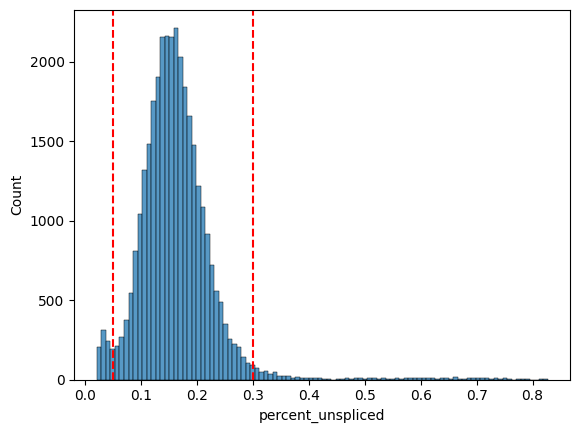

In [4]:
# plot distribution of % unspliced
sns.histplot(adata.obs["percent_unspliced"], bins=100)
# lower threshold for % unspliced
low_percent_unspliced = 0.05
# upper threshold for % unspliced
high_percent_unspliced = 0.3
plt.axvline(low_percent_unspliced, color="red", linestyle="--")
plt.axvline(high_percent_unspliced, color="red", linestyle="--")

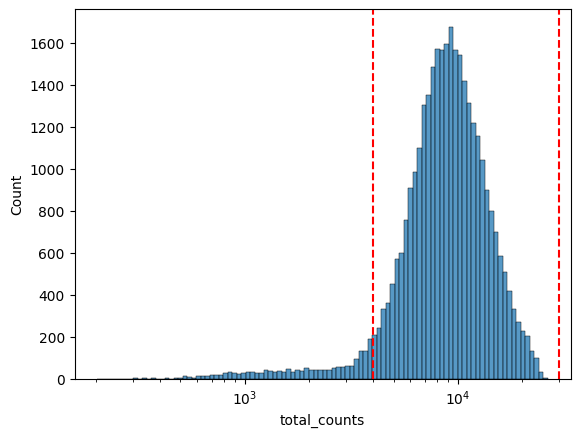

In [ ]:
# add total counts to adata.obs
adata.obs["total_counts"] = adata.layers["spliced"].sum(
    axis=1
)  
# plot distribution of total counts
sns.histplot(adata.obs["total_counts"], bins=100, log_scale=True)
# lower threshold for total counts
low_total_counts = 4000
# upper threshold for total counts
high_total_counts = 30000
plt.axvline(low_total_counts, color="red", linestyle="--")
plt.axvline(high_total_counts, color="red", linestyle="--")

In [6]:
# filter cells based on thresholds
adata = adata[
    (adata.obs["percent_unspliced"] > low_percent_unspliced)
    & (adata.obs["percent_unspliced"] < high_percent_unspliced)
    & (adata.obs["total_counts"] > low_total_counts)
    & (adata.obs["total_counts"] < high_total_counts)
].copy()

In [ ]:
adata.X = adata.layers["spliced"].copy()  
adata.var_names = adata.var_names.str.capitalize()
adata_all_genes = adata.copy()
layer_to_use = "spliced"
library_size = adata_all_genes.layers[layer_to_use].sum(axis=1)


In [8]:

# Preprocess data
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [9]:
adata.var.index = [a.upper() for a in adata.var.index]

## Subsetting cell cycle genes

In [11]:
SMALL_CYCLING_GENE_SET = gene_sets.SMALL_CELL_CYCLE_GENE_SET
SMALL_CYCLING_GENE_SET = [a.upper() for a in SMALL_CYCLING_GENE_SET]
adata = adata[:, adata.var_names.isin(SMALL_CYCLING_GENE_SET)]

In [13]:
# mean center the adata
adata.X = adata.X - adata.X.mean(axis=1, keepdims=True)
sc.pp.pca(adata)

# add PCA theta to adata.obs
adata.obs["pca_theta"] = np.arctan2(
    adata.obsm["X_pca"][:, 1], adata.obsm["X_pca"][:, 0]
)
adata_all_genes.obs["pca_theta"] = adata.obs["pca_theta"].copy()
adata = adata_all_genes.copy()



In [15]:
adata.var.index = [a.upper() for a in adata.var.index]

## Model training

In [16]:
g = utils.get_variable_genes(adata)
len(g)

2000

Epoch 1/200, elbo_loss: 1052.3053, kl_div_f: 4.6802, kl_div_z: 39.7683, l2_px_rate: 0.0000, entropy_loss_unweighted: -2.2190, entropy_loss: -221.8978, radial_variance: 7.7418, radius: 14.7363, L1_mu_z: 0.0000, MI_loss: 0.0000, total_loss: 852.8855
Epoch 2/200, elbo_loss: 926.6664, kl_div_f: 4.6211, kl_div_z: 41.5751, l2_px_rate: 0.0000, entropy_loss_unweighted: -2.9969, entropy_loss: -299.6889, radial_variance: 5.3619, radius: 7.7428, L1_mu_z: 0.0000, MI_loss: 0.0001, total_loss: 640.0876
Epoch 3/200, elbo_loss: 894.3994, kl_div_f: 4.5704, kl_div_z: 41.6035, l2_px_rate: 0.0000, entropy_loss_unweighted: -3.3248, entropy_loss: -332.4848, radial_variance: 2.3632, radius: 3.9307, L1_mu_z: 0.0000, MI_loss: 0.0009, total_loss: 568.2546
Epoch 4/200, elbo_loss: 871.0165, kl_div_f: 4.5020, kl_div_z: 41.6673, l2_px_rate: 0.0000, entropy_loss_unweighted: -3.3815, entropy_loss: -338.1489, radial_variance: 1.6551, radius: 3.5998, L1_mu_z: 0.0000, MI_loss: 0.0039, total_loss: 538.3162
Epoch 5/200, e

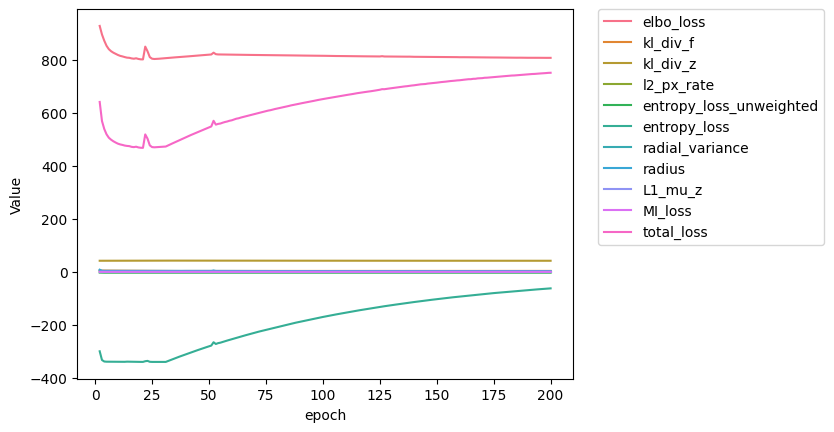

In [17]:
model = VAE_Rhythmic_Model(SMALL_CYCLING_GENE_SET, g, n_latent=10, n_harm=3)
model.load_anndata(adata, layer_to_use="spliced")
trainer = Trainer(
    model,
    Loss.compute_loss,
    noise_model="NB",
    non_rhythmic_likelihood_weight=1,
    rhythmic_likelihood_weight=1,
    calculate_entropy_per_batch=False,
    entropy_weight_factor=100,
    L2_Z_decoder_loss_weight=0,
    MI_weight=50,
    closed_circle_weight=10,
    cycling_status_prior=1,
)
trainer.train_model(
    n_epochs=200, lr=1e-2, batch_size=2048, record_wandb=False
)

## Theta-space

<Axes: ylabel='Count'>

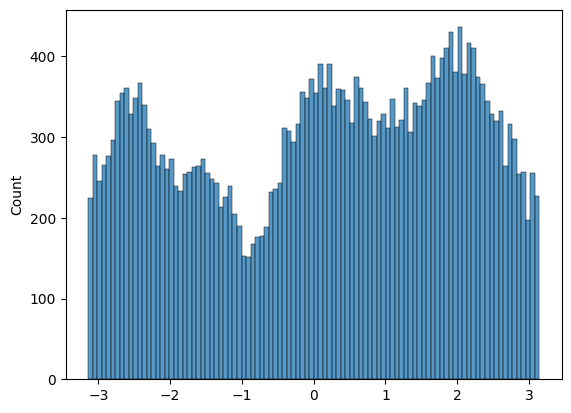

In [19]:
# Get the infered theta values
model.to("cpu")
generative_outputs, space_outputs = model.get_outputs()
thetas = space_outputs["theta"].detach().numpy()
sns.histplot(thetas, bins=100)

<Axes: >

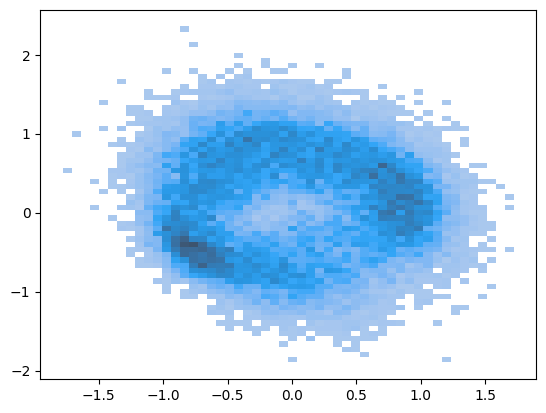

In [20]:
cells_projected = space_outputs["x_projected"].detach().numpy()
sns.histplot(x=cells_projected[:, 0], y=cells_projected[:, 1])

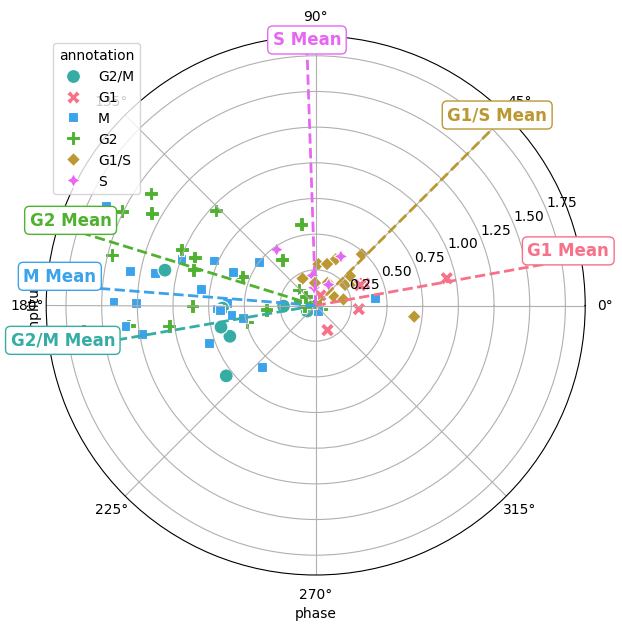

In [21]:

thetas = model.infer_pseudotimes(adata, "spliced", True)
adata.obs["inferred_theta"] = thetas

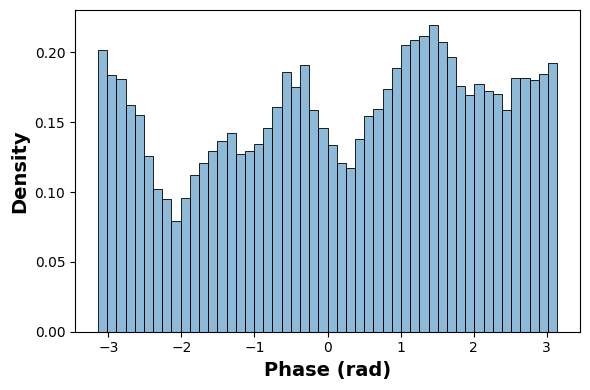

In [32]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    adata.obs['inferred_theta'],
    bins=50,
    binrange=(-np.pi, np.pi),
    stat='density',
    color='tab:blue',
    alpha=0.5,
    ax=ax
)

ax.set_xlabel('Phase (rad)', fontsize=14, fontweight='bold')
ax.set_ylabel('Density', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


#### Aligning phase to have mitosis at np.pi and going the right direction

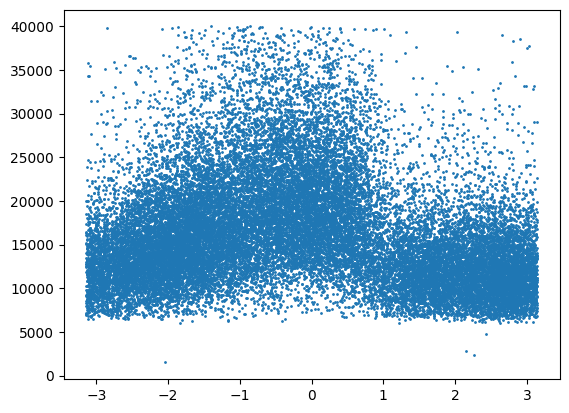

In [44]:
adata.obs['library_size'] = adata.obs['n_counts']
plt.scatter(adata.obs['inferred_theta'], adata.obs['library_size'], s = 1)

In [40]:
wrap_pi = lambda x: (x + np.pi) % (2*np.pi) - np.pi


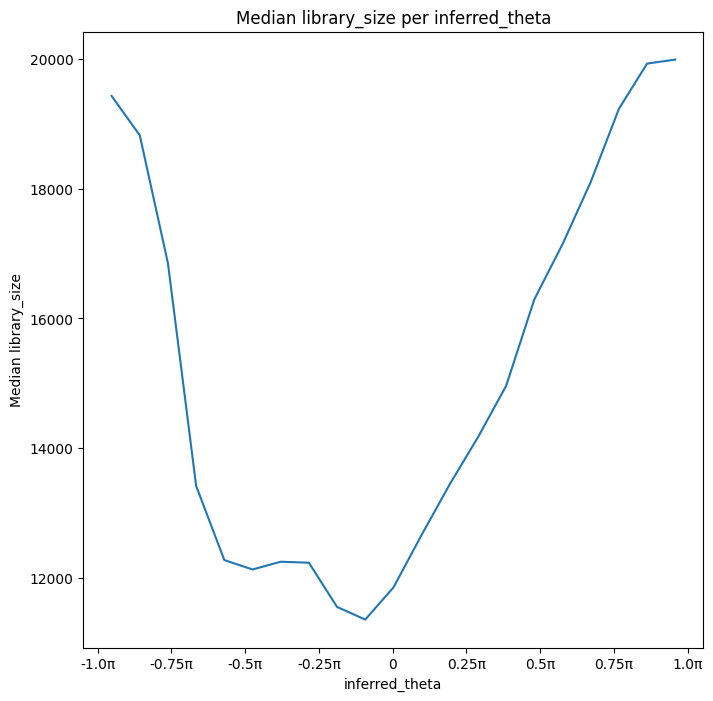

In [41]:
adata.obs['inferred_theta'] = wrap_pi(-adata.obs['inferred_theta'].astype(float))
plotting.plot_smoothed_size_evolution(adata, "inferred_theta")

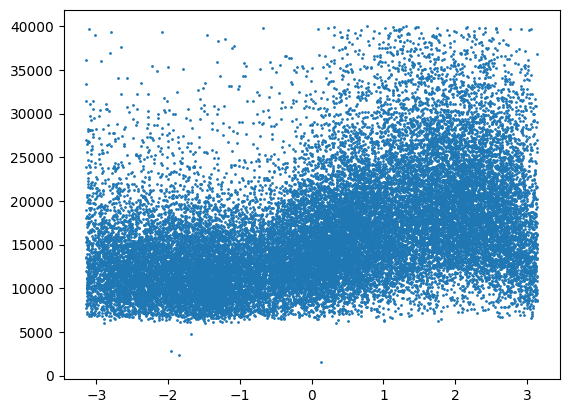

In [50]:
phase_shift = - np.pi/10
adata.obs['inferred_theta'] = wrap_pi(adata.obs['inferred_theta'].astype(float) + phase_shift)
plt.scatter(adata.obs['inferred_theta'], adata.obs['library_size'], s = 1)


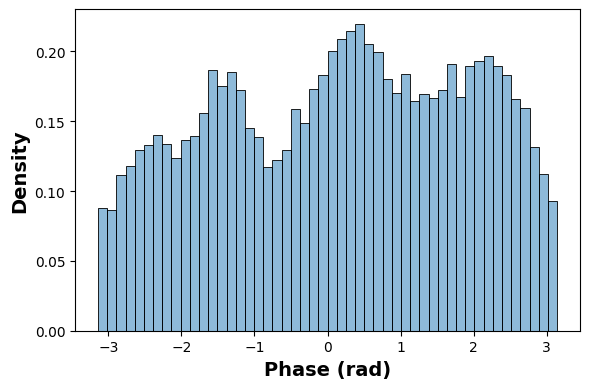

In [51]:


fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    adata.obs['inferred_theta'],
    bins=50,
    binrange=(-np.pi, np.pi),
    stat='density',
    color='tab:blue',
    alpha=0.5,
    ax=ax
)

ax.set_xlabel('Phase (rad)', fontsize=14, fontweight='bold')
ax.set_ylabel('Density', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


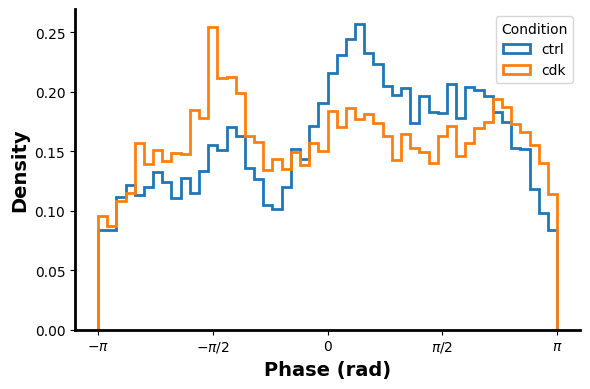

In [52]:

# ----------------------------
# Filter 
# ----------------------------
mask_base = (adata.obs["Condition"].str.lower().isin(["ctrl", "cdk"]))
df = adata.obs.loc[mask_base, ["inferred_theta", "Condition"]].copy()

# ----------------------------
# Plot
# ----------------------------
fig, ax = plt.subplots(figsize=(6, 4))

bins = 50
rng = (-np.pi, np.pi)
palette = {"ctrl": "tab:blue", "cdk": "tab:orange"}

for cond in ["ctrl", "cdk"]:
    x = df.loc[df["Condition"].str.lower() == cond, "inferred_theta"].astype(float).dropna().values
    if x.size == 0:
        continue

    ax.hist(
        x,
        bins=bins,
        range=rng,
        density=True,
        histtype="step",   # outline only so they overlay cleanly
        linewidth=2,
        color=palette[cond],
        label=cond
    )

ax.set_xlabel("Phase (rad)", fontsize=14, fontweight="bold")
ax.set_ylabel("Density", fontsize=14, fontweight="bold")

ticks = [-np.pi, -np.pi/2, 0, np.pi/2, np.pi]
labels = [r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"]
ax.set_xticks(ticks)
ax.set_xticklabels(labels)

ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(title="Condition")
plt.tight_layout()
plt.show()


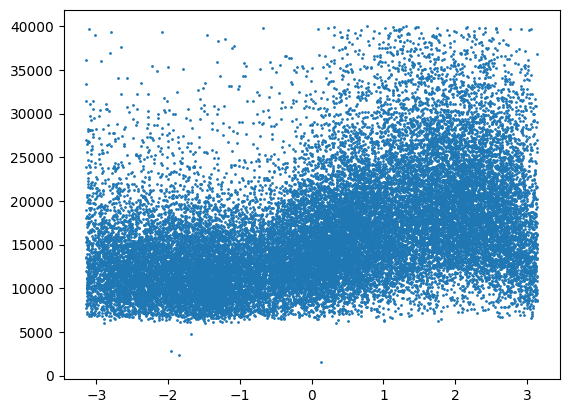

In [53]:
plt.scatter(adata.obs['inferred_theta'], adata.obs['n_counts'], s = 1)

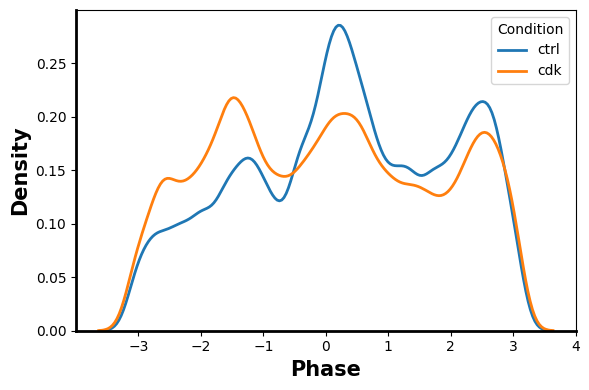

In [54]:

adata_plot = adata[
    (adata.obs['Time_int'] == 120) &
    (adata.obs['Condition'] != 'porcn')
].copy()

# Convert to DataFrame from the filtered AnnData
df = adata_plot.obs[['inferred_theta', 'Condition', 'Color']].copy()

# Conditions and palette
conditions = ['ctrl', 'cdk']
palette = {
    'ctrl': 'tab:blue',
    'cdk': 'tab:orange'
}

fig, ax = plt.subplots(figsize=(6, 4))

for cond in conditions:
    mask = df['Condition'].str.lower() == cond
    x = df.loc[mask, 'inferred_theta'].astype(float).dropna()

    if x.empty:
        continue

    sns.kdeplot(
        x=x,
        ax=ax,
        label=cond,
        color=palette[cond],
        bw_adjust=0.5,
        linewidth=2,
        fill=False  # line-only density
    )

ax.set_xlabel('Phase', fontsize=15, fontweight='bold')
ax.set_ylabel('Density', fontsize=15, fontweight='bold')

# Thicker axes spines
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.legend(title='Condition')

plt.tight_layout()
plt.show()


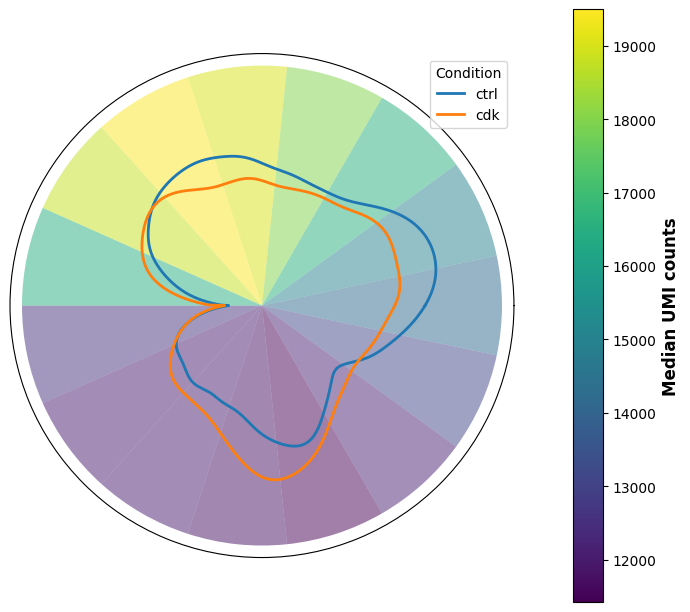

In [55]:


adata_plot = adata[
    (adata.obs['Time_int'] > 65) &
    (adata.obs['Condition'] != 'porcn')
].copy()

# Convert to DataFrame from the filtered AnnData
df = adata_plot.obs[['inferred_theta', 'Condition', 'n_counts']].copy()

# Conditions and palette
conditions = ['ctrl', 'cdk']
palette = {'ctrl': 'tab:blue', 'cdk': 'tab:orange'}

# ----------------------------
# Settings
# ----------------------------
bw_adjust = 0.5
n_bins = 15
theta_grid = np.linspace(-np.pi, np.pi, 512, endpoint=False)

# ----------------------------
# Background: median UMI counts vs angle
# ----------------------------
theta_bins = np.linspace(-np.pi, np.pi, n_bins + 1)
theta_centers = 0.5 * (theta_bins[:-1] + theta_bins[1:])
theta_centers_plot = (theta_centers + 2*np.pi) % (2*np.pi)

bg = np.zeros(n_bins, dtype=float)
theta_vals = df['inferred_theta'].astype(float).values
ncounts_vals = df['n_counts'].astype(float).values

for i in range(n_bins):
    m = (theta_vals >= theta_bins[i]) & (theta_vals < theta_bins[i+1])
    bg[i] = np.median(ncounts_vals[m])

# Normalisation for colormap
bg_min = np.nanmin(bg)
bg_max = np.nanmax(bg)
bg_norm = (bg - bg_min) / (bg_max - bg_min) if bg_max > bg_min else bg

# ----------------------------
# Polar plot
# ----------------------------
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

# Background ring
ax.bar(
    theta_centers_plot,
    height=0.3,
    width=(2*np.pi / n_bins),
    bottom=0.0,
    color=plt.cm.viridis(bg_norm),
    alpha=0.50,
    edgecolor='none',
    zorder=0
)

# ----------------------------
# KDE curves (per condition)
# ----------------------------
theta_plot = (theta_grid + 2*np.pi) % (2*np.pi)
order = np.argsort(theta_plot)
theta_plot_sorted = theta_plot[order]
theta_grid_sorted = theta_grid[order]

for cond in conditions:
    m = df['Condition'].str.lower() == cond
    x = df.loc[m, 'inferred_theta'].astype(float).dropna().values
    if x.size == 0:
        continue

    kde = gaussian_kde(x, bw_method=lambda s: s.scotts_factor() * bw_adjust)
    density = kde(theta_grid_sorted)

    th = np.r_[theta_plot_sorted, theta_plot_sorted[0] + 2*np.pi]
    rr = np.r_[density, density[0]]

    ax.plot(th, rr, color=palette[cond], lw=2, label=cond, zorder=2)

# ----------------------------
# Formatting 
# ----------------------------
ax.set_thetalim(0, 2*np.pi)
ax.set_theta_zero_location('E')
ax.set_theta_direction(1)

ax.set_xticks([])
ax.set_yticks([])
ax.set_ylabel(None)

ax.legend(title='Condition', loc='upper right')

# ----------------------------
# Colorbar for UMI counts
# ----------------------------
norm = Normalize(vmin=bg_min, vmax=bg_max)
sm = ScalarMappable(norm=norm, cmap='viridis')
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    pad=0.10,
    fraction=0.05
)
cbar.set_label(
    "Median UMI counts",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [56]:
adata.obs['theta_1'] = cells_projected[:, 0]
adata.obs['theta_2'] = cells_projected[:, 1]

## z-space

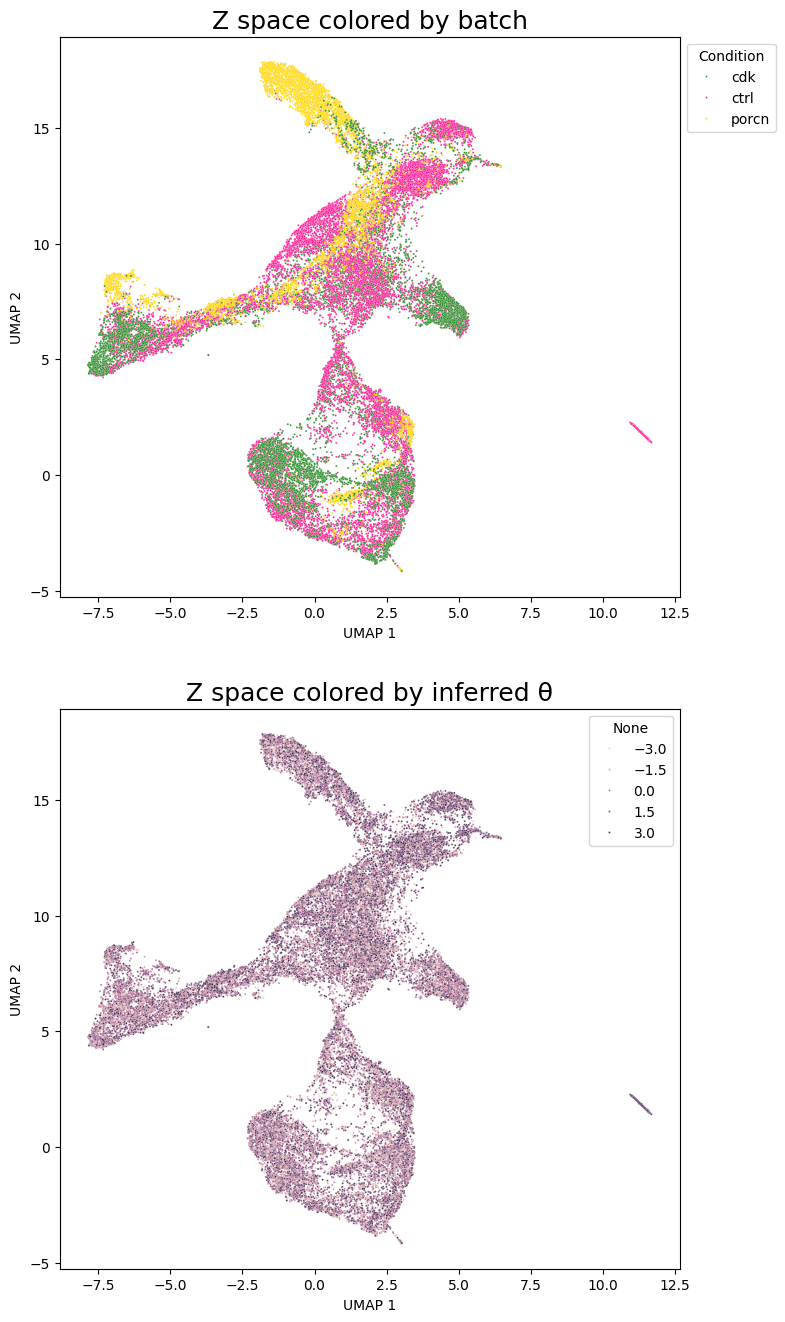

In [57]:
plotting.plot_z_space(
    z_space=space_outputs["z"][~adata.obs["Color"].isna()],
    hue_cell_identity=adata[~adata.obs["Color"].isna()]
    .obs["Condition"]
    .astype("category"),
    hue_time_component=thetas,
    cell_identity_label="batch",
    alpha=0.9,
    colors=adata[~adata.obs["Color"].isna()].obs["Color"].values,
)

<Axes: >

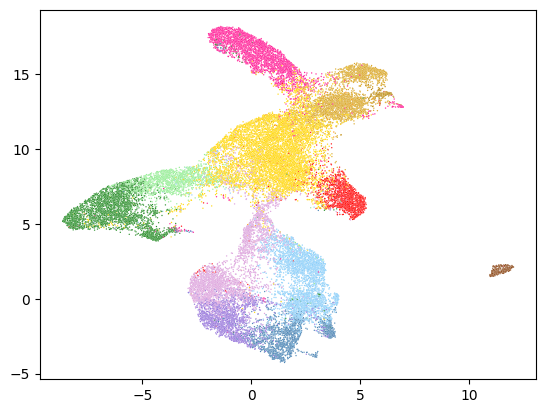

In [61]:


reducer = umap.UMAP(min_dist=0.2)
i = adata.obs["Condition"].isin(["ctrl", "cdk", "porcn"])
z_space = space_outputs["z"][i]
embedding = reducer.fit_transform(z_space.numpy())

sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], c=adata[i].obs["Color"], s=1)

<Axes: >

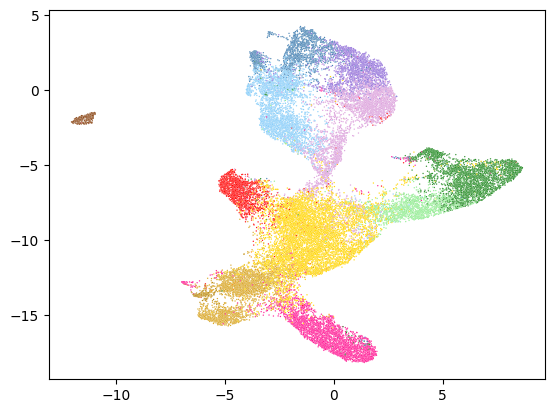

In [62]:
sns.scatterplot(x=-embedding[:, 0], y=-embedding[:, 1], c=adata[i].obs["Color"], s=1)

In [63]:

X = -embedding[:, 0]
Y = -embedding[:, 1]

# --------------------------------------------------
# Save back to adata.obs
# --------------------------------------------------
adata.obs["Z_space1"] = np.nan
adata.obs["Z_space2"] = np.nan
adata.obs.loc[mask, "Z_space1"] = X
adata.obs.loc[mask, "Z_space2"] = Y

In [65]:
adata.obs.to_csv('INPUT/scRNAseq/theta_Zspace_annotation2.csv')